In [11]:
import sys
import os
import json
import random
import matplotlib.pyplot as plt
from IPython.display import clear_output

import geopandas as gpd


sys.path.append('../')
import model.dataloader as dataloader
from model.dataset import LABEL_MAPPING


In [12]:
inverse_label_mapping = {value : key for key, value in LABEL_MAPPING.items()}

In [13]:
_id = 'fuvmj0ci'


In [14]:


model_dir = os.path.join('../models_trained', _id)
config_path = os.path.join(model_dir, 'config.json')
with open(config_path) as source:
    config = json.loads(source.read())


    


In [5]:
import pandas as pd

In [6]:
df = pd.read_csv('/home/jan/Documents/EPFL/project_2/data/labels/dataset_v5/labels_no_regrowth.csv')

In [9]:
df

,driver,sampleid,dataset,country,geometry,block_id,split,dst_size
0,cocoa,170000000,cocoa_peru_points.csv,Peru,POINT (-78.1800924591649 -4.4448238378139076),66.0,0,20000.0
1,cocoa,170000002,cocoa_peru_points.csv,Peru,POINT (-76.32138830479319 -6.303527986575525),67.0,3,20000.0
2,cocoa,170000003,cocoa_peru_points.csv,Peru,POINT (-76.11684191459916 -6.312421307861641),67.0,3,20000.0
3,cocoa,170000004,cocoa_peru_points.csv,Peru,POINT (-75.77000238340061 -6.347994593006127),67.0,3,20000.0
4,cocoa,170000005,cocoa_peru_points.csv,Peru,POINT (-76.0545886654097 -6.365781235578377),67.0,3,20000.0
...,...,...,...,...,...,...,...,...
30366,forest plantation,10698584,mapbiomas.csv,Brazil,POINT (-50.31072642972264 -30.155633046502274),14.0,0,NaN
30367,forest plantation,80063592,mapbiomas_indonesia.csv,Indonesia,POINT (102.87698944468539 0.6374894394167583),202.0,3,2000.0
30368,forest plantation,10686066,mapbiomas.csv,Brazil,POINT (-49.310767598259304 -22.112163750390017),32.0,3,20000.0
30369,forest plantation,10649958,mapbiomas.csv,Brazil,POINT (-41.58247137745064 -15.758425504011205),46.0,0,2000.0


In [16]:
# fetch dataloaders
dataloaders = dataloader.fetch_dataloader(
    ['val'], config)
val_dl = dataloaders['val']

                 driver   sampleid                dataset     country  \
0                coffee  190000083  manual_annotation.csv  Costa Rica   
1                coffee  190000084  manual_annotation.csv  Costa Rica   
2                coffee  190000085  manual_annotation.csv  Costa Rica   
3                coffee  190000086  manual_annotation.csv  Costa Rica   
4                coffee  190000087  manual_annotation.csv  Costa Rica   
...                 ...        ...                    ...         ...   
4750  forest plantation   10655614          mapbiomas.csv      Brazil   
4751  forest plantation   10655563          mapbiomas.csv      Brazil   
4752  forest plantation   10656797          mapbiomas.csv      Brazil   
4753  forest plantation   10653072          mapbiomas.csv      Brazil   
4754  forest plantation   10654747          mapbiomas.csv      Brazil   

                         geometry  block_id split  dst_size  
0      POINT (-84.25407 10.14892)      92.0   val       NaN  

In [18]:
x,y = next(iter(val_dl))

In [23]:
def plot_images(data, label):
    
    n_images = data.shape[0]
    print(label)
    fig, ax = plt.subplots(1,n_images, figsize=(16, 10))
    idx = 0
    for idx in range(n_images):
        img = data[idx, :3, :, :].detach()
        img = img/0.25

        ax[idx].imshow(img.permute(1, 2, 0)[:,:,[2,1,0]].numpy()  )
        ax[idx].set_xticks([])
        ax[idx].set_yticks([])



    fig.tight_layout()
    plt.show()
    
def plot_images_with_tmf(data, tmf, label):
    
    n_images = data.shape[0]
    print(label)
    fig, ax = plt.subplots(1,n_images+1, figsize=(16, 16))
    idx = 0
    for idx in range(n_images):
        img = data[idx, :3, :, :].detach()
        img = img/0.25

        ax[idx].imshow(img.permute(1, 2, 0)[:,:,[2,1,0]].numpy()  )
        ax[idx].set_xticks([])
        ax[idx].set_yticks([])

    ax[n_images].imshow(tmf.permute(1, 2, 0).numpy())
    ax[n_images].set_xticks([])
    ax[n_images].set_yticks([])
    
    fig.tight_layout()
    plt.show()
    



In [31]:
import numpy as np

array([0.11, 0.27, 0.12, 0.  , 0.02,  nan,  nan,  nan, 0.82,  nan,  nan],
      dtype=float32)

In [43]:
import pprint

pprint.pprint(rates)

{'cocoa': nan,
 'coffee': 0.0,
 'forest plantation': 0.27,
 'mining': nan,
 'other': nan,
 'palm oil': 0.02,
 'pasture': 0.11,
 'rubber': 0.82,
 'shifting agriculture': nan,
 'soy': 0.12,
 'urban': nan}


In [34]:
LABEL_MAPPING = {
    'pasture' : 0, 
    'forest plantation' : 1,
    'soy' : 2,
    'coffee' : 3,
    'palm oil': 4,
    'mining': 5,
    'urban': 6,
    'cocoa': 7,
    'rubber': 8,
    'shifting agriculture': 9,
    'other': 10 
}

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


driver                                             mining
sampleid                                        140032878
dataset                                         mines.csv
country                                          Cambodia
geometry    POINT (106.78993498196921 12.629727209806376)
block_id                                             18.0
split                                                 val
dst_size                                              NaN
Name: 449, dtype: object
tensor([1.0626e-01, 2.7330e-01, 1.1870e-01, 1.5788e-04, 2.4635e-02,        nan,
               nan,        nan, 8.1817e-01,        nan,        nan])
mining


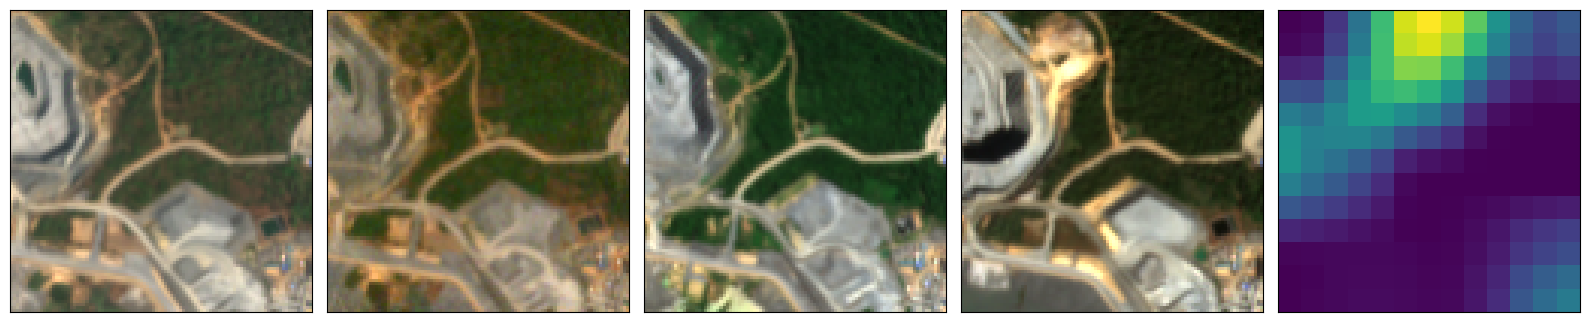

KeyboardInterrupt: Interrupted by user

In [25]:
for _i, row in val_dl.dataset.img_labels.loc[val_dl.dataset.img_labels.country == 'Cambodia'].iterrows():
    i = row.name

    x, label = val_dl.dataset.__getitem__(i)
    ts, loc, expansion_rates, forestloss = x 
    print(row)

    ratessss = np.around(expansion_rates.numpy(),decimals=2)
    rates = {}
    for i, key in enumerate(LABEL_MAPPING.keys()):
        rates[key] = ratessss[i]

    plot_images_with_tmf(ts, forestloss, label= inverse_label_mapping[label])

    _waitforinput = input()

    clear_output(wait=True)

driver                                            coffee
sampleid                                       190000251
dataset                            manual_annotation.csv
country                                         Ethiopia
geometry    POINT (35.469560345379854 6.880993470519291)
block_id                                           154.0
split                                                val
Name: 96, dtype: object
PREDICTION:  coffee
coffee


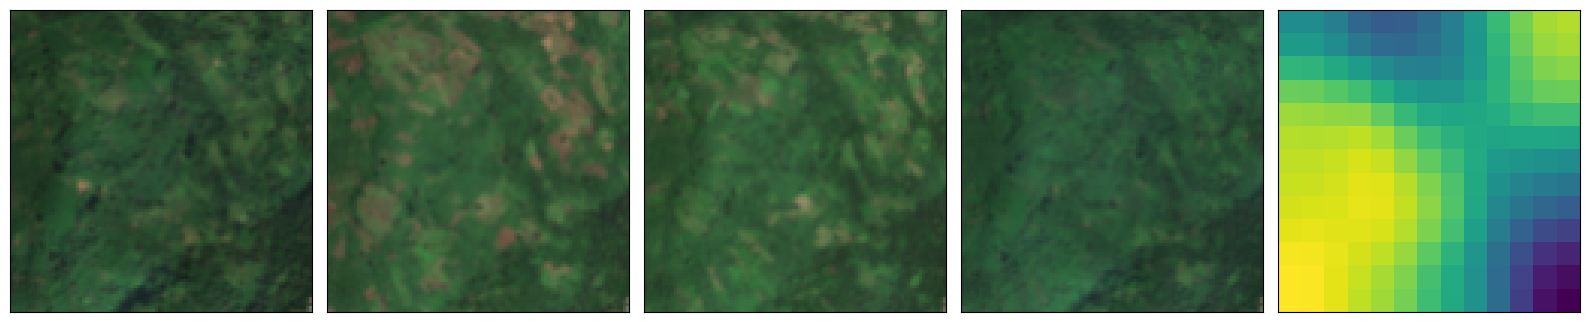

KeyboardInterrupt: Interrupted by user

In [57]:
for _i, row in val_dl.dataset.img_labels.loc[val_dl.dataset.img_labels.country == 'Ethiopia'].iterrows():
    i = row.name
    print(val_dl.dataset.img_labels.iloc[i])
    print('PREDICTION: ', xx.loc[xx.sampleid == row.sampleid].preds.values[0])
    x, label = val_dl.dataset.__getitem__(i)
    ts, loc, expansion_rates, forestloss = x 

    plot_images_with_tmf(ts, forestloss, label= inverse_label_mapping[label])

    _waitforinput = input()

    clear_output(wait=True)

0

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


80084343
forest plantation


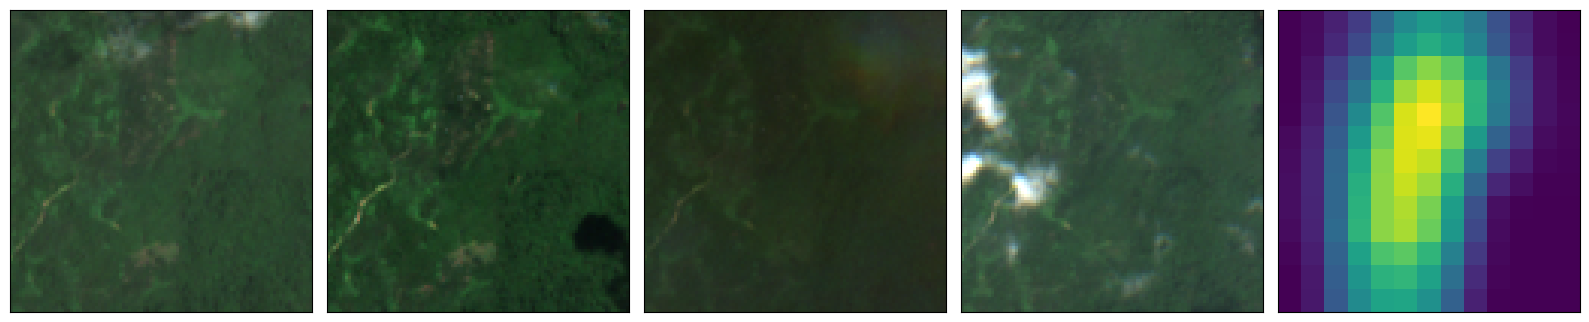

KeyboardInterrupt: Interrupted by user

In [21]:
dataset = val_dl.dataset

while True:

    i = random.randint(0,len(dataset.img_labels))
    #if not train_dataset.img_labels.iloc[i].driver == 'shifting agriculture':
    #    continue
    
    
    print(dataset.img_labels.iloc[i].sampleid)
    x, label = val_dl.dataset.__getitem__(i)
    ts, loc, expansion_rates, forestloss = x 

    plot_images_with_tmf(ts, forestloss, label= inverse_label_mapping[label])

    _waitforinput = input()

    clear_output(wait=True)

    
    
    
    

In [ ]:
sampleids = [
2040330, #forest plant. looks like palm oil
    5000927, #forest plant. looks like palm oil
    8118421,  #forest plant. looks like palm oil
]

In [21]:
train_dataset.img_labels.loc[train_dataset.img_labels.sampleid == 5002879]

,geometry,driver,sampleid,split
7438,POINT (105.97349049958846 14.335897554805385),shifting agriculture,5002879,train


## Visualize time series with TMF